<a href="https://colab.research.google.com/github/SobiaNoorAI/cross-network-nids/blob/main/notebooks/cross_network_nids.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 1: Setup

Install and import

In [1]:
# Cell 1: Install and import
!pip install -q xgboost shap pyarrow

import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)

DATA_DIR = "/content/data"
OUT_DIR = "/content/outputs"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
print("Ready. Folders created.")

Ready. Folders created.


Check how much free space I have

In [2]:
# Cell 2: Check disk space
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   85M  108G   1% /


Download the smaller dataset (UNSW-NB15)

In [3]:
# Cell 3: Download NF-UNSW-NB15-v2
url_unsw = "https://rdm.uq.edu.au/files/8c6e2a00-ef9c-11ed-827d-e762de186848"
!wget -q --show-progress -O /content/data/unsw_download "{url_unsw}"

!ls -lh /content/data
!file /content/data/unsw_download

/content/data/unsw_ 100%[===================>]   1.88K  --.-KB/s    in 0s      
total 4.0K
-rw-r--r-- 1 root root 1.9K Nov 18 23:04 unsw_download
/content/data/unsw_download: HTML document, ASCII text


In [5]:
!mv /content/data/unsw_download /content/data/NF-UNSW-NB15-v2.csv

Download the bigger dataset (CSE-CIC-IDS2018)

In [6]:
# Cell 5: Download NF-CSE-CIC-IDS2018-v2 (LARGE: may take 5-20 minutes)
url_cse = "https://rdm.uq.edu.au/files/ce5161d0-ef9c-11ed-827d-e762de186848"
!wget -q --show-progress -O /content/data/cse_download "{url_cse}"

!ls -lh /content/data
!file /content/data/cse_download

/content/data/cse_d 100%[===================>]   1.88K  --.-KB/s    in 0s      
total 8.0K
-rw-r--r-- 1 root root 1.9K Nov 18 23:04 cse_download
-rw-r--r-- 1 root root 1.9K Nov 18 23:04 NF-UNSW-NB15-v2.csv
/content/data/cse_download: HTML document, ASCII text


Find CSV file names

In [7]:
# Cell 6: List the CSV files
csv_files = glob.glob("/content/data/**/*.csv", recursive=True)
for f in csv_files:
    print(f, f"({os.path.getsize(f)/1e6:.0f} MB)")

/content/data/NF-UNSW-NB15-v2.csv (0 MB)


In [8]:
# Cell A: Remove the fake CSV and peek inside the downloaded web page
!rm -f /content/data/NF-UNSW-NB15-v2.csv
print(open("/content/data/cse_download", errors="ignore").read()[:1500])

<!doctype html>
<html lang="en">
  <head>
    <script>window.SENTRY_RELEASE={id:"bb729b667d6cc96fa7ae3c21e3ed86d652812037"}</script>

    <meta charset="utf-8" />
    <base href="/" />
    <meta name="uqrdm-app" content="web" />

    <meta name="viewport" content="initial-scale=1, width=device-width" />
    <link rel="icon" type="image/x-icon" href="/favicon.ico" />
    <!-- Roboto + Atkinson Hyperlegible are self-hosted via @fontsource imports in
         main.tsx (bundled, hashed, immutable-cached). -->
    <link rel="stylesheet" href="style.css" />
    <script>
      // Start the session check while the app bundle downloads instead of after it has parsed;
      // attemptAuth (@rdm/shared-ui) adopts this response. Mirrors its marker/refresh-cookie precondition:
      // no stored session or no 'rdm-browser-session' marker (storedSession.ts), and an SSO refresh
      // cookie. An expired or corrupt stored session is left to attemptAuth after the bundle parses.
      try {
        if

Test a second source (Hugging Face mirror)

In [10]:
# Cell B: Peek at the Hugging Face copy (streaming = no big download)
!pip install -q datasets
from datasets import load_dataset

ds = load_dataset("Jetlime/NF-CSE-CIC-IDS2018-v2", split="train", streaming=True)
for i, row in enumerate(ds):
    print(row)
    print("-" * 60)
    if i == 2:
        break

DatasetNotFoundError: Dataset 'Jetlime/NF-CSE-CIC-IDS2018-v2' doesn't exist on the Hub or cannot be accessed.

Unzip Dataset

In [11]:
!cd /content && unzip -o "NF-UNSW-NB15-v2.zip"

Archive:  NF-UNSW-NB15-v2.zip
  inflating: fe6cb615d161452c_MOHANAD_A4706/FurtherInformation.txt  
  inflating: fe6cb615d161452c_MOHANAD_A4706/bag-info.txt  
 extracting: fe6cb615d161452c_MOHANAD_A4706/bagit.txt  
  inflating: fe6cb615d161452c_MOHANAD_A4706/manifest-sha1.txt  
  inflating: fe6cb615d161452c_MOHANAD_A4706/tagmanifest-sha1.txt  
  inflating: fe6cb615d161452c_MOHANAD_A4706/data/NF-UNSW-NB15-v2.csv  
  inflating: fe6cb615d161452c_MOHANAD_A4706/data/NetFlow_v2_Features.csv  


Find the file and peek at it

In [12]:
# Cell 2: Find the UNSW file
csv_files = [f for f in glob.glob("/content/**/*.csv", recursive=True)
             if "sample_data" not in f]
for f in csv_files:
    print(f, f"({os.path.getsize(f)/1e6:.0f} MB)")

UNSW_FILE = csv_files[0]          # change the number if you see more than one file
print("\nUsing:", UNSW_FILE)
print(pd.read_csv(UNSW_FILE, nrows=3))

/content/fe6cb615d161452c_MOHANAD_A4706/data/NF-UNSW-NB15-v2.csv (442 MB)
/content/fe6cb615d161452c_MOHANAD_A4706/data/NetFlow_v2_Features.csv (0 MB)

Using: /content/fe6cb615d161452c_MOHANAD_A4706/data/NF-UNSW-NB15-v2.csv
  IPV4_SRC_ADDR  L4_SRC_PORT  IPV4_DST_ADDR  L4_DST_PORT  PROTOCOL  L7_PROTO  \
0    59.166.0.5         1305  149.171.126.8           21         6       1.0   
1    59.166.0.5         1305  149.171.126.8           21         6       1.0   
2    59.166.0.5         1305  149.171.126.8           21         6       1.0   

   IN_BYTES  IN_PKTS  OUT_BYTES  OUT_PKTS  TCP_FLAGS  CLIENT_TCP_FLAGS  \
0         9        1        193         3         24                24   
1       261        5        469         7         24                24   
2       481        9        750        11         24                24   

   SERVER_TCP_FLAGS  FLOW_DURATION_MILLISECONDS  DURATION_IN  DURATION_OUT  \
0                16                           0            0             0   
1  

Load a random 30% sample (memory-safe)

In [13]:
# Cell 3: Read in chunks, keep a random 30%
def load_sample(path, frac, seed=42, chunksize=500_000):
    pieces = []
    start = time.time()
    for i, chunk in enumerate(pd.read_csv(path, chunksize=chunksize, low_memory=False)):
        pieces.append(chunk.sample(frac=frac, random_state=seed))
        print(f"  chunk {i+1} done ({time.time()-start:.0f}s)", end="\r")
    df = pd.concat(pieces, ignore_index=True)
    print(f"\nLoaded {len(df):,} rows")
    return df

df_unsw = load_sample(UNSW_FILE, frac=0.30)


Loaded 717,082 rows


Inspect the sample

In [14]:
# Cell 4: Inspect
print("Shape:", df_unsw.shape)
print("\nColumns:", list(df_unsw.columns))

print("\nLabel counts (0 = benign, 1 = attack):")
print(df_unsw["Label"].value_counts())

print("\nAttack types:")
print(df_unsw["Attack"].value_counts())

print("\nMissing values:", int(df_unsw.isna().sum().sum()))
print("Duplicate rows:", int(df_unsw.duplicated().sum()))
print("\nData types:")
print(df_unsw.dtypes.value_counts())

Shape: (717082, 45)

Columns: ['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack']

Label counts (0 = benign, 1 = attack):
Label
0    688797
1     28285
Name: count, dtype: int6

Save the sample and download it to your computer

In [15]:
# Cell 5: Save a compact copy and download it
df_unsw.to_parquet(f"{OUT_DIR}/unsw_v2_sample.parquet")
print("Saved. Size:", round(os.path.getsize(f"{OUT_DIR}/unsw_v2_sample.parquet")/1e6), "MB")

from google.colab import files
files.download(f"{OUT_DIR}/unsw_v2_sample.parquet")

Saved. Size: 28 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Unzip and find the CSV

In [18]:
# Cell 6: Unzip ToN-IoT and find the CSV
!cd /content && unzip -o -q "NF-ToN-IoT-v2.zip"

ton_files = [f for f in glob.glob("/content/**/*.csv", recursive=True)
             if "ToN" in os.path.basename(f) and "Features" not in f]
for f in ton_files:
    print(f, f"({os.path.getsize(f)/1e6:.0f} MB)")

TON_FILE = ton_files[0]
print("\nUsing:", TON_FILE)

/content/9bafce9d380588c2_MOHANAD_A4706/data/NF-ToN-IoT-v2.csv (2676 MB)

Using: /content/9bafce9d380588c2_MOHANAD_A4706/data/NF-ToN-IoT-v2.csv


Check the columns match UNSW

In [19]:
# Cell 7: Peek and compare columns
peek = pd.read_csv(TON_FILE, nrows=3)
print(peek.iloc[:, :8])

same_cols = list(peek.columns) == list(df_unsw.columns)
print("\nSame columns, same order as UNSW?", same_cols)
if not same_cols:
    print("In UNSW only:", set(df_unsw.columns) - set(peek.columns))
    print("In ToN only: ", set(peek.columns) - set(df_unsw.columns))

   IPV4_SRC_ADDR  L4_SRC_PORT  IPV4_DST_ADDR  L4_DST_PORT  PROTOCOL  L7_PROTO  \
0  192.168.1.193        49235   192.168.1.33         4444         6       0.0   
1  192.168.1.193        49228  192.168.1.152         1880         6       0.0   
2  192.168.1.152            0  192.168.1.193            0         1       0.0   

   IN_BYTES  IN_PKTS  
0    155392      202  
1      1600       40  
2       212        2  

Same columns, same order as UNSW? True


Load a 5% sample of ToN-IoT

In [20]:
# Cell 8: Read in chunks, keep a random 5%
# if said file not found, rerun Cell 3
df_ton = load_sample(TON_FILE, frac=0.05)


Loaded 847,025 rows


Compare the two datasets

In [21]:
# Cell 9: Side-by-side comparison
for name, df in [("UNSW-NB15-v2", df_unsw), ("ToN-IoT-v2", df_ton)]:
    n_attack = int(df["Label"].sum())
    print(f"{name}: {len(df):,} rows | attacks: {n_attack:,} ({100*n_attack/len(df):.1f}%)")
    print("  Missing:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
    print("  Attack types:", df["Attack"].value_counts().to_dict())
    print()

UNSW-NB15-v2: 717,082 rows | attacks: 28,285 (3.9%)
  Missing: 0 | Duplicates: 0
  Attack types: {'Benign': 688797, 'Exploits': 9351, 'Fuzzers': 6537, 'Generic': 4992, 'Reconnaissance': 3841, 'DoS': 1727, 'Analysis': 690, 'Backdoor': 646, 'Shellcode': 446, 'Worms': 55}

ToN-IoT-v2: 847,025 rows | attacks: 542,479 (64.0%)
  Missing: 0 | Duplicates: 0
  Attack types: {'Benign': 304546, 'scanning': 189387, 'xss': 122861, 'ddos': 101693, 'password': 57681, 'dos': 35551, 'injection': 33926, 'backdoor': 811, 'mitm': 366, 'ransomware': 203}



Save and download the samples

In [22]:
# Cell 10: Save and download ToN-IoT sample
df_ton.to_parquet(f"{OUT_DIR}/ton_v2_sample.parquet")
print("Size:", round(os.path.getsize(f"{OUT_DIR}/ton_v2_sample.parquet")/1e6), "MB")

from google.colab import files
files.download(f"{OUT_DIR}/ton_v2_sample.parquet")

Size: 20 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 2: Clean the features and run the main experiment

Decide which columns the model may use

In [23]:
# Cell 11: Define the feature sets
TARGET = "Label"
DROP_ALWAYS = ["Attack", "IPV4_SRC_ADDR", "IPV4_DST_ADDR"]
PORTS = ["L4_SRC_PORT", "L4_DST_PORT"]

all_cols = list(df_unsw.columns)

feature_sets = {
    "A_with_ports": [c for c in all_cols if c not in DROP_ALWAYS + [TARGET]],
    "B_no_ports":   [c for c in all_cols if c not in DROP_ALWAYS + PORTS + [TARGET]],
}
print({name: len(cols) for name, cols in feature_sets.items()})

{'A_with_ports': 41, 'B_no_ports': 39}


In [26]:
# Cell 11b: Find and fix infinite / huge values
SKIP = ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Attack"]
num_cols = [c for c in df_unsw.columns if c not in SKIP]

# Step 1: report where the bad values are
for name, df in [("UNSW", df_unsw), ("ToN-IoT", df_ton)]:
    vals = df[num_cols].astype("float64")
    bad = (vals.abs() > 1e15).sum()      # also catches inf and -inf
    bad = bad[bad > 0]
    print(f"{name}: columns with inf/huge values")
    print(bad if len(bad) else "  none")
    print()

# Step 2: replace them with NaN (XGBoost can handle NaN)
def clean(df):
    df = df.copy()
    vals = df[num_cols].astype("float64")
    df[num_cols] = vals.mask(vals.abs() > 1e15)
    return df

df_unsw = clean(df_unsw)
df_ton = clean(df_ton)

print("NaN cells after cleaning:",
      "UNSW =", int(df_unsw[num_cols].isna().sum().sum()),
      "| ToN-IoT =", int(df_ton[num_cols].isna().sum().sum()))

UNSW: columns with inf/huge values
  none

ToN-IoT: columns with inf/huge values
SRC_TO_DST_SECOND_BYTES    17
DST_TO_SRC_SECOND_BYTES    16
dtype: int64

NaN cells after cleaning: UNSW = 0 | ToN-IoT = 33


Split each dataset into train and test

In [27]:
# Cell 12: Train/test split (80% / 20%)
from sklearn.model_selection import train_test_split

def make_split(df):
    return train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=42)

splits = {
    "UNSW":    make_split(df_unsw),
    "ToN-IoT": make_split(df_ton),
}
for name, (tr, te) in splits.items():
    print(f"{name}: train {len(tr):,} | test {len(te):,} | attack rate in test {te[TARGET].mean():.3f}")

UNSW: train 573,665 | test 143,417 | attack rate in test 0.039
ToN-IoT: train 677,620 | test 169,405 | attack rate in test 0.640


Train XGBoost and test it on both networks

In [28]:
# Cell 13: Train 4 models, test each on both datasets
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, matthews_corrcoef)

def evaluate(model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "Accuracy":  accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall":    recall_score(y, pred),
        "F1":        f1_score(y, pred),
        "ROC_AUC":   roc_auc_score(y, proba),
        "MCC":       matthews_corrcoef(y, pred),
    }

rows = []
for fs_name, cols in feature_sets.items():
    for train_name, (tr, _) in splits.items():
        t0 = time.time()
        model = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1,
                              tree_method="hist", n_jobs=-1,
                              eval_metric="logloss", random_state=42)
        model.fit(tr[cols], tr[TARGET])

        for test_name, (_, te) in splits.items():
            scores = evaluate(model, te[cols], te[TARGET])
            rows.append({"features": fs_name, "train": train_name, "test": test_name,
                         "setting": "within" if train_name == test_name else "cross",
                         **scores})
        print(f"Done: {fs_name} | trained on {train_name} ({time.time()-t0:.0f}s)")

results = pd.DataFrame(rows).round(4)
results.to_csv(f"{OUT_DIR}/results_xgb.csv", index=False)
results

Done: A_with_ports | trained on UNSW (26s)
Done: A_with_ports | trained on ToN-IoT (29s)
Done: B_no_ports | trained on UNSW (17s)
Done: B_no_ports | trained on ToN-IoT (29s)


,features,train,test,setting,Accuracy,Precision,Recall,F1,ROC_AUC,MCC
0,A_with_ports,UNSW,UNSW,within,0.9973,0.9576,0.9738,0.9656,0.9997,0.9643
1,A_with_ports,UNSW,ToN-IoT,cross,0.3601,0.5162,0.0138,0.0268,0.3225,-0.0341
2,A_with_ports,ToN-IoT,UNSW,cross,0.4692,0.0205,0.2664,0.0381,0.4125,-0.0997
3,A_with_ports,ToN-IoT,ToN-IoT,within,0.9943,0.9936,0.9975,0.9956,0.9996,0.9876
4,B_no_ports,UNSW,UNSW,within,0.9970,0.9526,0.9735,0.9629,0.9997,0.9615
5,B_no_ports,UNSW,ToN-IoT,cross,0.3541,0.3378,0.0088,0.0172,0.3528,-0.0822
6,B_no_ports,ToN-IoT,UNSW,cross,0.8790,0.0158,0.0338,0.0215,0.2383,-0.0368
7,B_no_ports,ToN-IoT,ToN-IoT,within,0.9940,0.9933,0.9973,0.9953,0.9996,0.9870


Draw the main chart

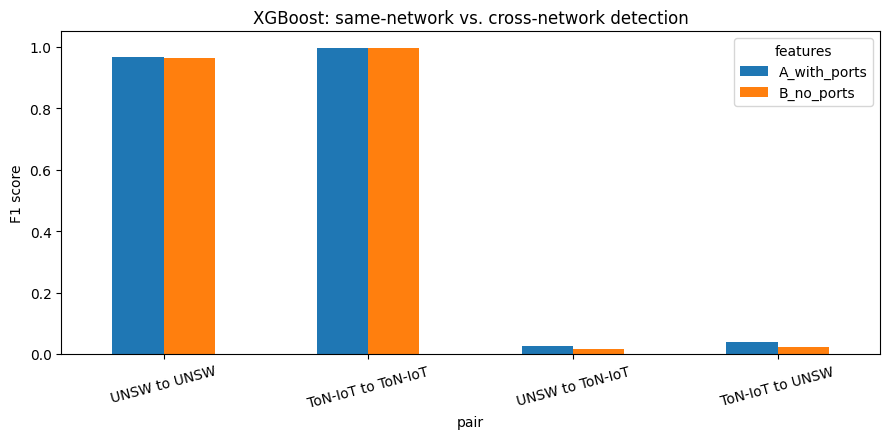

In [29]:
# Cell 14: Bar chart of F1 scores
results["pair"] = results["train"] + " to " + results["test"]
pivot = results.pivot(index="pair", columns="features", values="F1")
pivot = pivot.loc[["UNSW to UNSW", "ToN-IoT to ToN-IoT", "UNSW to ToN-IoT", "ToN-IoT to UNSW"]]

ax = pivot.plot(kind="bar", figsize=(9, 4.5))
ax.set_ylabel("F1 score")
ax.set_ylim(0, 1.05)
ax.set_title("XGBoost: same-network vs. cross-network detection")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_f1_within_vs_cross.png", dpi=200)
plt.show()

Save figure and table to computer

In [30]:
# Cell 14b: Download results
from google.colab import files
files.download(f"{OUT_DIR}/results_xgb.csv")
files.download(f"{OUT_DIR}/fig_f1_within_vs_cross.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phase 3: Find out why it fails

Look at the mistakes

In [31]:
# Cell 15: Retrain the no-ports models and inspect their errors
from sklearn.metrics import confusion_matrix

cols = feature_sets["B_no_ports"]
models = {}
for name, (tr, _) in splits.items():
    m = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1,
                      tree_method="hist", n_jobs=-1,
                      eval_metric="logloss", random_state=42)
    m.fit(tr[cols], tr[TARGET])
    models[name] = m

for train_name in models:
    for test_name, (_, te) in splits.items():
        proba = models[train_name].predict_proba(te[cols])[:, 1]
        pred = (proba >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(te[TARGET], pred).ravel()
        print(f"Train {train_name} -> Test {test_name}")
        print(f"  real attack rate: {te[TARGET].mean():.3f} | predicted attack rate: {pred.mean():.3f}")
        print(f"  attacks caught (TP): {tp:,} | attacks missed (FN): {fn:,}")
        print(f"  false alarms (FP): {fp:,} | benign correct (TN): {tn:,}\n")

Train UNSW -> Test UNSW
  real attack rate: 0.039 | predicted attack rate: 0.040
  attacks caught (TP): 5,507 | attacks missed (FN): 150
  false alarms (FP): 274 | benign correct (TN): 137,486

Train UNSW -> Test ToN-IoT
  real attack rate: 0.640 | predicted attack rate: 0.017
  attacks caught (TP): 955 | attacks missed (FN): 107,541
  false alarms (FP): 1,872 | benign correct (TN): 59,037

Train ToN-IoT -> Test UNSW
  real attack rate: 0.039 | predicted attack rate: 0.084
  attacks caught (TP): 191 | attacks missed (FN): 5,466
  false alarms (FP): 11,885 | benign correct (TN): 125,875

Train ToN-IoT -> Test ToN-IoT
  real attack rate: 0.640 | predicted attack rate: 0.643
  attacks caught (TP): 108,205 | attacks missed (FN): 291
  false alarms (FP): 725 | benign correct (TN): 60,184



Which features look different between the networks?

,feature,KS,UNSW_median,ToN_median
0,DST_TO_SRC_AVG_THROUGHPUT,0.775,13552000.0,320000.0
1,SRC_TO_DST_AVG_THROUGHPUT,0.775,10616000.0,384000.0
2,LONGEST_FLOW_PKT,0.705,485.0,48.0
3,MAX_IP_PKT_LEN,0.705,485.0,48.0
4,OUT_BYTES,0.697,2456.0,40.0
5,RETRANSMITTED_OUT_PKTS,0.695,4.0,0.0
6,RETRANSMITTED_OUT_BYTES,0.695,871.0,0.0
7,RETRANSMITTED_IN_BYTES,0.693,506.0,0.0
8,RETRANSMITTED_IN_PKTS,0.693,3.0,0.0
9,ICMP_IPV4_TYPE,0.692,43.0,0.0


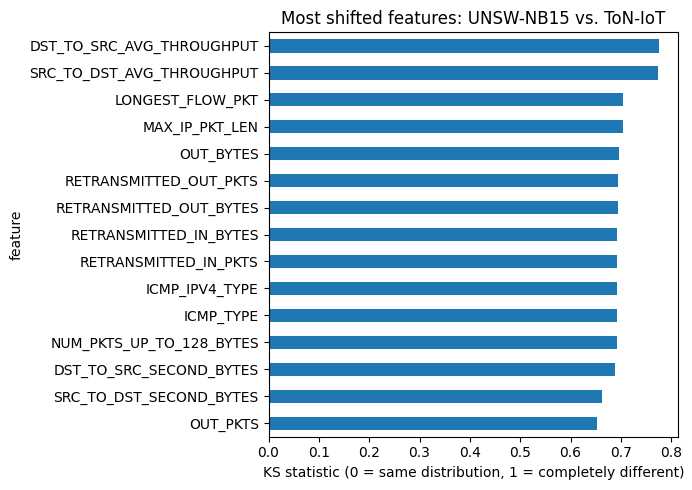

In [32]:
# Cell 16: Feature distribution shift (KS statistic)
from scipy.stats import ks_2samp

u = df_unsw[cols].sample(50_000, random_state=42)
t = df_ton[cols].sample(50_000, random_state=42)

rows = []
for c in cols:
    a, b = u[c].dropna(), t[c].dropna()
    rows.append({"feature": c,
                 "KS": ks_2samp(a, b).statistic,
                 "UNSW_median": a.median(),
                 "ToN_median": b.median()})

shift = pd.DataFrame(rows).sort_values("KS", ascending=False).reset_index(drop=True)
shift.to_csv(f"{OUT_DIR}/feature_shift.csv", index=False)
display(shift.head(15).round(3))

ax = shift.head(15).iloc[::-1].plot(kind="barh", x="feature", y="KS",
                                    legend=False, figsize=(7, 5))
ax.set_xlabel("KS statistic (0 = same distribution, 1 = completely different)")
ax.set_title("Most shifted features: UNSW-NB15 vs. ToN-IoT")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_feature_shift.png", dpi=200)
plt.show()

First easy fix: normalize each network on its own

In [33]:
# Cell 17: Per-network quantile normalization
from sklearn.preprocessing import QuantileTransformer

qts = {}
for name, (tr, _) in splits.items():
    qt = QuantileTransformer(n_quantiles=1000, output_distribution="uniform",
                             subsample=200_000, random_state=42)
    qt.fit(tr[cols])
    qts[name] = qt

def transform(df, name):
    return pd.DataFrame(qts[name].transform(df[cols]), columns=cols, index=df.index)

rows = []
for train_name, (tr, _) in splits.items():
    m = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1,
                      tree_method="hist", n_jobs=-1,
                      eval_metric="logloss", random_state=42)
    m.fit(transform(tr, train_name), tr[TARGET])
    for test_name, (_, te) in splits.items():
        scores = evaluate(m, transform(te, test_name), te[TARGET])
        rows.append({"method": "per-network quantile", "train": train_name,
                     "test": test_name,
                     "setting": "within" if train_name == test_name else "cross",
                     **scores})

res_qt = pd.DataFrame(rows).round(4)
res_qt.to_csv(f"{OUT_DIR}/results_quantile.csv", index=False)
res_qt

,method,train,test,setting,Accuracy,Precision,Recall,F1,ROC_AUC,MCC
0,per-network quantile,UNSW,UNSW,within,0.9970,0.9529,0.9731,0.9629,0.9997,0.9614
1,per-network quantile,UNSW,ToN-IoT,cross,0.3634,0.9635,0.0063,0.0126,0.3957,0.0438
2,per-network quantile,ToN-IoT,UNSW,cross,0.5978,0.0152,0.1446,0.0276,0.4112,-0.0961
3,per-network quantile,ToN-IoT,ToN-IoT,within,0.9939,0.9931,0.9973,0.9952,0.9996,0.9867


Which direction does each feature point?

In [34]:
# Cell 18: Class medians per dataset + ICMP artifact check
top = shift.head(8)["feature"].tolist()
combo = pd.concat([
    df_unsw[top + ["Label"]].assign(dataset="UNSW"),
    df_ton[top + ["Label"]].assign(dataset="ToN-IoT"),
])
combo["class"] = combo["Label"].map({0: "benign", 1: "attack"})
display(combo.groupby(["dataset", "class"])[top].median().T)

print("Attack names in ToN-IoT:")
print(df_ton["Attack"].value_counts())

for name, df in [("UNSW", df_unsw), ("ToN-IoT", df_ton)]:
    non_icmp = df[df["PROTOCOL"] != 1]
    share = (non_icmp["ICMP_TYPE"] != 0).mean()
    print(f"{name}: share of non-ICMP flows with ICMP_TYPE != 0 = {share:.3f}")

dataset                     ToN-IoT                 UNSW            
class                        attack    benign     attack      benign
DST_TO_SRC_AVG_THROUGHPUT  320000.0       0.0  2048000.0  14984000.0
SRC_TO_DST_AVG_THROUGHPUT  384000.0  352000.0  4176000.0  11664000.0
LONGEST_FLOW_PKT               60.0      44.0      122.0       736.0
MAX_IP_PKT_LEN                 60.0      44.0      122.0       736.0
OUT_BYTES                      81.0       0.0      256.0      2512.0
RETRANSMITTED_OUT_PKTS          0.0       0.0        0.0         5.0
RETRANSMITTED_OUT_BYTES         0.0       0.0        0.0       887.0
RETRANSMITTED_IN_BYTES          0.0       0.0      100.0       506.0

Attack names in ToN-IoT:
Attack
Benign        304546
scanning      189387
xss           122861
ddos          101693
password       57681
dos            35551
injection      33926
backdoor         811
mitm             366
ransomware       203
Name: count, dtype: int64
UNSW: share of non-ICMP flows with ICMP_TYPE != 0 = 0.709
ToN-IoT: share of non-ICMP flows with ICMP_TYPE != 0 = 0.016


Test only the attack families both datasets share

In [35]:
# Cell 19: Shared-family experiment (benign + DoS + Backdoor + Recon/scanning)
fam_map = {"benign": "benign", "dos": "dos", "backdoor": "backdoor",
           "reconnaissance": "recon", "scanning": "recon"}

def shared(df):
    fam = df["Attack"].str.lower().map(fam_map)
    keep = fam.notna()
    return df[keep].assign(family=fam[keep])

rows = []
for train_name in splits:
    tr = shared(splits[train_name][0])
    m = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1,
                      tree_method="hist", n_jobs=-1,
                      eval_metric="logloss", random_state=42)
    m.fit(tr[cols], tr[TARGET])
    for test_name in splits:
        te = shared(splits[test_name][1])
        proba = m.predict_proba(te[cols])[:, 1]
        flagged = pd.Series(proba >= 0.5, index=te.index)
        fam_rate = flagged.groupby(te["family"]).mean().round(3).to_dict()
        rows.append({"train": train_name, "test": test_name,
                     **{k: round(v, 4) for k, v in evaluate(m, te[cols], te[TARGET]).items()
                        if k in ("F1", "ROC_AUC", "MCC")},
                     "flagged_by_family": fam_rate})

res_shared = pd.DataFrame(rows)
res_shared.to_csv(f"{OUT_DIR}/results_shared_families.csv", index=False)
pd.set_option("display.max_colwidth", 120)
res_shared

,train,test,F1,ROC_AUC,MCC,flagged_by_family
0,UNSW,UNSW,0.9556,0.9999,0.9552,"{'backdoor': 0.964, 'benign': 0.0, 'dos': 0.877, 'recon': 0.999}"
1,UNSW,ToN-IoT,0.0168,0.6793,-0.0690,"{'backdoor': 0.593, 'benign': 0.028, 'dos': 0.042, 'recon': 0.0}"
2,ToN-IoT,UNSW,0.0064,0.2881,0.0166,"{'backdoor': 0.007, 'benign': 0.0, 'dos': 0.006, 'recon': 0.001}"
3,ToN-IoT,ToN-IoT,0.9897,0.9996,0.9821,"{'backdoor': 1.0, 'benign': 0.01, 'dos': 0.996, 'recon': 0.993}"


Does removing the most-shifted features help?

k=0 done (39 features left)
k=5 done (34 features left)
k=10 done (29 features left)
k=15 done (24 features left)
k=20 done (19 features left)
k=25 done (14 features left)


,dropped,train,test,F1,ROC_AUC,MCC
0,0,UNSW,ToN-IoT,0.0172,0.2986,-0.0823
1,0,ToN-IoT,UNSW,0.0177,0.2216,-0.0527
2,5,UNSW,ToN-IoT,0.0276,0.4012,-0.0809
3,5,ToN-IoT,UNSW,0.0215,0.2992,-0.0279
4,10,UNSW,ToN-IoT,0.0301,0.3477,-0.0762
5,10,ToN-IoT,UNSW,0.0272,0.3361,0.0017
6,15,UNSW,ToN-IoT,0.0103,0.3247,-0.1126
7,15,ToN-IoT,UNSW,0.0315,0.3154,0.0069
8,20,UNSW,ToN-IoT,0.0125,0.2804,-0.1287
9,20,ToN-IoT,UNSW,0.0082,0.3874,-0.0437


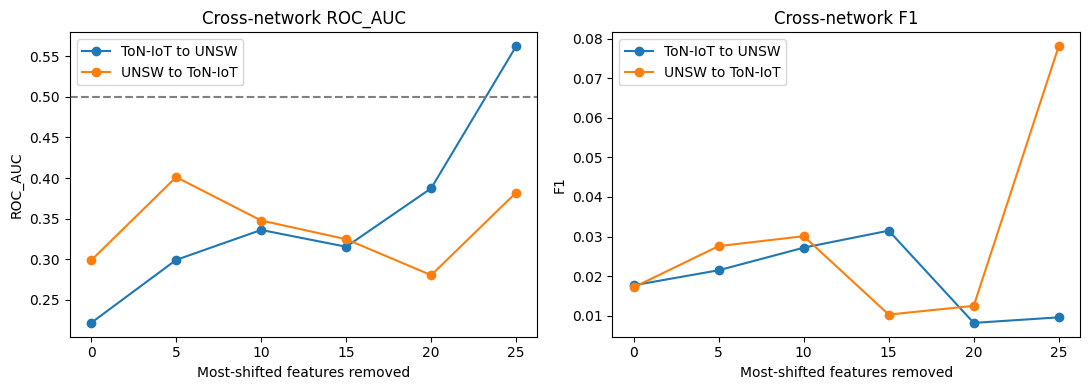

In [36]:
# Cell 20: Drop the k most-shifted features, retest cross-network
ranked = shift["feature"].tolist()          # most shifted first
rows = []
for k in [0, 5, 10, 15, 20, 25]:
    use = [c for c in cols if c not in ranked[:k]]
    for train_name, (tr, _) in splits.items():
        m = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1,
                          tree_method="hist", n_jobs=-1,
                          eval_metric="logloss", random_state=42)
        m.fit(tr[use], tr[TARGET])
        for test_name, (_, te) in splits.items():
            if test_name == train_name:
                continue
            s = evaluate(m, te[use], te[TARGET])
            rows.append({"dropped": k, "train": train_name, "test": test_name,
                         "F1": s["F1"], "ROC_AUC": s["ROC_AUC"], "MCC": s["MCC"]})
    print(f"k={k} done ({len(use)} features left)")

res_prune = pd.DataFrame(rows).round(4)
res_prune.to_csv(f"{OUT_DIR}/results_pruning.csv", index=False)
display(res_prune)

res_prune["direction"] = res_prune["train"] + " to " + res_prune["test"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["ROC_AUC", "F1"]):
    for d, g in res_prune.groupby("direction"):
        ax.plot(g["dropped"], g[metric], marker="o", label=d)
    ax.set_xlabel("Most-shifted features removed")
    ax.set_ylabel(metric)
    ax.set_title(f"Cross-network {metric}")
    ax.legend()
axes[0].axhline(0.5, ls="--", color="gray")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_pruning.png", dpi=200)
plt.show()

How much labeled data from the new network is needed?

UNSW -> ToN-IoT done
ToN-IoT -> UNSW done


,source,target,labeled_target_flows,attacks_among_them,F1,Recall,ROC_AUC
0,UNSW,ToN-IoT,0,0,0.0172,0.0088,0.2986
1,UNSW,ToN-IoT,50,35,0.9406,0.9526,0.9623
2,UNSW,ToN-IoT,200,120,0.9592,0.9721,0.9875
3,UNSW,ToN-IoT,1000,628,0.9740,0.9798,0.9935
4,UNSW,ToN-IoT,5000,3216,0.9840,0.9845,0.9966
5,ToN-IoT,UNSW,0,0,0.0177,0.0361,0.2216
6,ToN-IoT,UNSW,50,3,0.3970,0.3730,0.8263
7,ToN-IoT,UNSW,200,7,0.6262,0.4851,0.8865
8,ToN-IoT,UNSW,1000,34,0.8877,0.8596,0.9980
9,ToN-IoT,UNSW,5000,189,0.9229,0.9380,0.9985


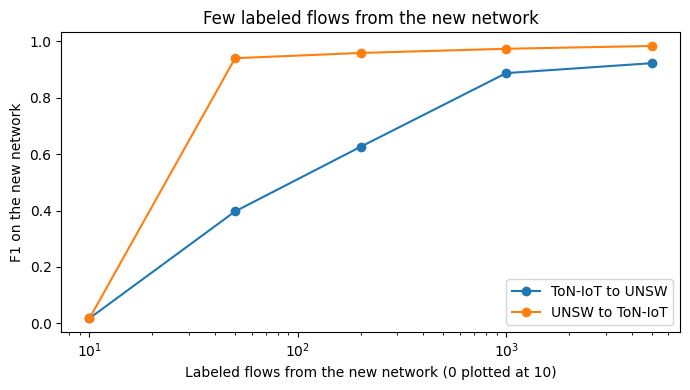

In [37]:
# Cell 21: Add a few labeled flows from the target network
ns = [0, 50, 200, 1000, 5000]
W = 20          # each labeled target flow counts 20x in training
rows = []
for src, tgt in [("UNSW", "ToN-IoT"), ("ToN-IoT", "UNSW")]:
    src_tr = splits[src][0]
    tgt_tr, tgt_te = splits[tgt]
    for n in ns:
        if n == 0:
            X, y, w = src_tr[cols], src_tr[TARGET], np.ones(len(src_tr))
            n_att = 0
        else:
            sub = tgt_tr.sample(n, random_state=42)
            n_att = int(sub[TARGET].sum())
            X = pd.concat([src_tr[cols], sub[cols]])
            y = pd.concat([src_tr[TARGET], sub[TARGET]])
            w = np.concatenate([np.ones(len(src_tr)), np.full(n, W)])
        m = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1,
                          tree_method="hist", n_jobs=-1,
                          eval_metric="logloss", random_state=42)
        m.fit(X, y, sample_weight=w)
        s = evaluate(m, tgt_te[cols], tgt_te[TARGET])
        rows.append({"source": src, "target": tgt, "labeled_target_flows": n,
                     "attacks_among_them": n_att,
                     "F1": s["F1"], "Recall": s["Recall"], "ROC_AUC": s["ROC_AUC"]})
    print(f"{src} -> {tgt} done")

res_fs = pd.DataFrame(rows).round(4)
res_fs.to_csv(f"{OUT_DIR}/results_few_labels.csv", index=False)
display(res_fs)

fig, ax = plt.subplots(figsize=(7, 4))
for (s_, t_), g in res_fs.groupby(["source", "target"]):
    ax.plot(g["labeled_target_flows"].replace(0, 10), g["F1"], marker="o", label=f"{s_} to {t_}")
ax.set_xscale("log")
ax.set_xlabel("Labeled flows from the new network (0 plotted at 10)")
ax.set_ylabel("F1 on the new network")
ax.set_title("Few labeled flows from the new network")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_few_labels.png", dpi=200)
plt.show()

A fair, repeatable few-label test (5 random seeds)

UNSW -> ToN-IoT: 5 attacks done
UNSW -> ToN-IoT: 10 attacks done
UNSW -> ToN-IoT: 25 attacks done
UNSW -> ToN-IoT: 50 attacks done
UNSW -> ToN-IoT: 100 attacks done
ToN-IoT -> UNSW: 5 attacks done
ToN-IoT -> UNSW: 10 attacks done
ToN-IoT -> UNSW: 25 attacks done
ToN-IoT -> UNSW: 50 attacks done
ToN-IoT -> UNSW: 100 attacks done


F1        Recall       
                          mean    std   mean    std
source  target  attacks                            
ToN-IoT UNSW    0        0.018  0.000  0.036  0.000
                5        0.396  0.144  0.470  0.137
                10       0.580  0.080  0.629  0.125
                25       0.828  0.089  0.960  0.013
                50       0.900  0.078  0.974  0.014
                100      0.937  0.004  0.987  0.006
UNSW    ToN-IoT 0        0.017  0.000  0.009  0.000
                5        0.504  0.085  0.387  0.064
                10       0.713  0.069  0.603  0.118
                25       0.860  0.046  0.804  0.087
                50       0.924  0.016  0.911  0.029
                100      0.952  0.006  0.952  0.012

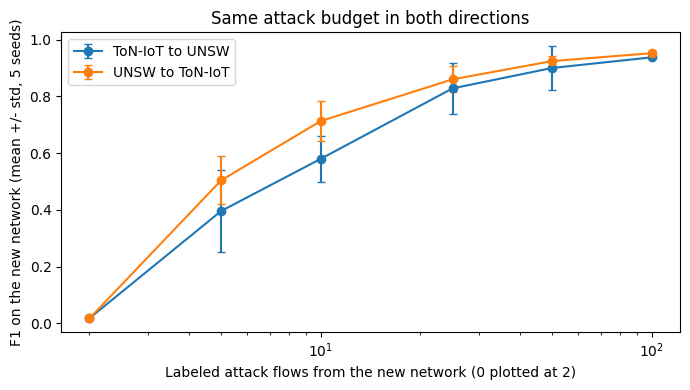

In [38]:
# Cell 22: Equal number of attacks in both directions, 5 seeds, mean +/- std
attack_budgets = [0, 5, 10, 25, 50, 100]   # labeled ATTACK flows from the new network
benign_ratio = 1                            # same number of labeled benign flows
SEEDS = [1, 2, 3, 4, 5]                     # use [1, 2, 3] for a quicker run
W = 20

def fit_eval(X, y, w, te):
    m = XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1,
                      tree_method="hist", n_jobs=-1,
                      eval_metric="logloss", random_state=42)
    m.fit(X, y, sample_weight=w)
    return evaluate(m, te[cols], te[TARGET])

rows = []
for src, tgt in [("UNSW", "ToN-IoT"), ("ToN-IoT", "UNSW")]:
    src_tr = splits[src][0]
    tgt_tr, tgt_te = splits[tgt]
    att_pool = tgt_tr[tgt_tr[TARGET] == 1]
    ben_pool = tgt_tr[tgt_tr[TARGET] == 0]
    for n_att in attack_budgets:
        if n_att == 0:
            s = fit_eval(src_tr[cols], src_tr[TARGET], np.ones(len(src_tr)), tgt_te)
            for seed in SEEDS:
                rows.append({"source": src, "target": tgt, "attacks": 0, "seed": seed,
                             "F1": s["F1"], "Recall": s["Recall"]})
            continue
        for seed in SEEDS:
            sub = pd.concat([att_pool.sample(n_att, random_state=seed),
                             ben_pool.sample(n_att * benign_ratio, random_state=seed)])
            X = pd.concat([src_tr[cols], sub[cols]])
            y = pd.concat([src_tr[TARGET], sub[TARGET]])
            w = np.concatenate([np.ones(len(src_tr)), np.full(len(sub), W)])
            s = fit_eval(X, y, w, tgt_te)
            rows.append({"source": src, "target": tgt, "attacks": n_att, "seed": seed,
                         "F1": s["F1"], "Recall": s["Recall"]})
        print(f"{src} -> {tgt}: {n_att} attacks done")

raw = pd.DataFrame(rows)
raw.to_csv(f"{OUT_DIR}/results_few_labels_seeds_raw.csv", index=False)
summ = (raw.groupby(["source", "target", "attacks"])[["F1", "Recall"]]
           .agg(["mean", "std"]).round(3))
display(summ)

fig, ax = plt.subplots(figsize=(7, 4))
for (s_, t_), g in raw.groupby(["source", "target"]):
    st = g.groupby("attacks")["F1"].agg(["mean", "std"]).reset_index()
    ax.errorbar(st["attacks"].replace(0, 2), st["mean"], yerr=st["std"],
                marker="o", capsize=3, label=f"{s_} to {t_}")
ax.set_xscale("log")
ax.set_xlabel("Labeled attack flows from the new network (0 plotted at 2)")
ax.set_ylabel("F1 on the new network (mean +/- std, 5 seeds)")
ax.set_title("Same attack budget in both directions")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_few_labels_seeds.png", dpi=200)
plt.show()

Explain the models with SHAP

/tmp/ipykernel_666/1654559211.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(x[ok], sv[ok, j]).correlation
/tmp/ipykernel_666/1654559211.py:20: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(x[ok], sv[ok, j]).correlation


,UNSW,ToN-IoT,UNSW_dir,ToN-IoT_dir,opposite_direction
MIN_TTL,7.204,0.026,0.300,0.742,False
LONGEST_FLOW_PKT,0.088,2.839,-0.534,0.347,True
SERVER_TCP_FLAGS,1.736,0.141,-0.795,0.851,True
TCP_WIN_MAX_IN,0.395,0.897,-0.877,0.727,True
L7_PROTO,0.067,0.970,0.751,0.438,False
SRC_TO_DST_SECOND_BYTES,0.264,0.229,-0.671,0.420,True
FLOW_DURATION_MILLISECONDS,0.059,0.422,-0.387,0.292,True
SRC_TO_DST_AVG_THROUGHPUT,0.040,0.335,0.110,0.106,False
NUM_PKTS_UP_TO_128_BYTES,0.198,0.164,-0.083,0.844,True
TCP_FLAGS,0.015,0.306,0.245,-0.156,True


Top-10 overlap between the two networks: 3 of 10


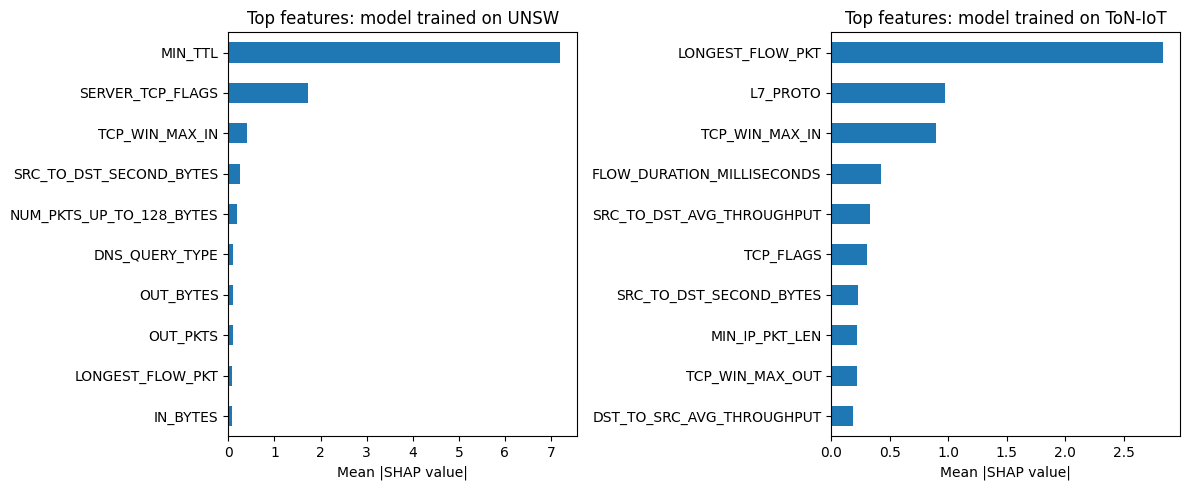

In [39]:
# Cell 23: SHAP importance and direction per network
import shap
from scipy.stats import spearmanr

shap_data = {}
for name, (_, te) in splits.items():
    smp = te[cols].sample(5000, random_state=42)
    sv = shap.TreeExplainer(models[name]).shap_values(smp)
    shap_data[name] = (smp, np.asarray(sv))

imp = pd.DataFrame({n: np.abs(sv).mean(axis=0) for n, (smp, sv) in shap_data.items()},
                   index=cols)

def direction(name, j):
    smp, sv = shap_data[name]
    x = smp.iloc[:, j]
    ok = x.notna().values
    if x[ok].nunique() < 2:
        return np.nan
    return spearmanr(x[ok], sv[ok, j]).correlation

for n in shap_data:
    imp[f"{n}_dir"] = [direction(n, j) for j in range(len(cols))]

top = sorted(set(imp["UNSW"].nlargest(10).index) | set(imp["ToN-IoT"].nlargest(10).index),
             key=lambda c: -(imp.loc[c, "UNSW"] + imp.loc[c, "ToN-IoT"]))
table = imp.loc[top].round(3)
table["opposite_direction"] = (table["UNSW_dir"] * table["ToN-IoT_dir"]) < 0
table.to_csv(f"{OUT_DIR}/shap_summary.csv")
display(table)

print("Top-10 overlap between the two networks:",
      len(set(imp["UNSW"].nlargest(10).index) & set(imp["ToN-IoT"].nlargest(10).index)), "of 10")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, n in zip(axes, ["UNSW", "ToN-IoT"]):
    imp[n].nlargest(10).iloc[::-1].plot(kind="barh", ax=ax)
    ax.set_title(f"Top features: model trained on {n}")
    ax.set_xlabel("Mean |SHAP value|")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_shap_top_features.png", dpi=200)
plt.show()

Is MIN_TTL a shortcut?

In [40]:
# Cell 24: Look at MIN_TTL, then retrain without the TTL features
for name, df in [("UNSW", df_unsw), ("ToN-IoT", df_ton)]:
    print(name, "- most common MIN_TTL values (share of flows):")
    for lab, lab_name in [(0, "benign"), (1, "attack")]:
        vc = df.loc[df[TARGET] == lab, "MIN_TTL"].value_counts(normalize=True).head(5)
        print(f"   {lab_name}: {vc.round(3).to_dict()}")
    print()

no_ttl = [c for c in cols if c not in ("MIN_TTL", "MAX_TTL")]
rows = []
for train_name, (tr, _) in splits.items():
    m = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1,
                      tree_method="hist", n_jobs=-1,
                      eval_metric="logloss", random_state=42)
    m.fit(tr[no_ttl], tr[TARGET])
    for test_name, (_, te) in splits.items():
        s = evaluate(m, te[no_ttl], te[TARGET])
        rows.append({"train": train_name, "test": test_name,
                     "F1_no_TTL": s["F1"], "AUC_no_TTL": s["ROC_AUC"]})
abl = pd.DataFrame(rows)

base = (results[results["features"] == "B_no_ports"][["train", "test", "F1", "ROC_AUC"]]
        .rename(columns={"F1": "F1_all", "ROC_AUC": "AUC_all"}))
cmp_ttl = base.merge(abl, on=["train", "test"]).round(4)
cmp_ttl.to_csv(f"{OUT_DIR}/results_ttl_ablation.csv", index=False)
display(cmp_ttl)

UNSW - most common MIN_TTL values (share of flows):
   benign: {31.0: 0.984, 0.0: 0.005, 254.0: 0.005, 62.0: 0.003, 29.0: 0.002}
   attack: {254.0: 0.749, 62.0: 0.249, 0.0: 0.002}

ToN-IoT - most common MIN_TTL values (share of flows):
   benign: {0.0: 0.848, 64.0: 0.123, 128.0: 0.018, 1.0: 0.003, 37.0: 0.002}
   attack: {0.0: 0.527, 64.0: 0.461, 71.0: 0.005, 234.0: 0.005, 128.0: 0.002}



,train,test,F1_all,AUC_all,F1_no_TTL,AUC_no_TTL
0,UNSW,UNSW,0.9629,0.9997,0.9618,0.9997
1,UNSW,ToN-IoT,0.0172,0.3528,0.0399,0.4490
2,ToN-IoT,UNSW,0.0215,0.2383,0.0096,0.4679
3,ToN-IoT,ToN-IoT,0.9953,0.9996,0.9952,0.9996


A simple robustness (sensitivity) test

,network,features_changed,attack_detection_rate,changed
0,UNSW,0,0.9735,
1,UNSW,1,0.0014,MIN_TTL
2,UNSW,2,0.0000,"MIN_TTL, SERVER_TCP_FLAGS"
3,UNSW,3,0.0000,"MIN_TTL, SERVER_TCP_FLAGS, TCP_WIN_MAX_IN"
4,UNSW,5,0.0000,"MIN_TTL, SERVER_TCP_FLAGS, TCP_WIN_MAX_IN, SRC_TO_DST_SECOND_BYTES, NUM_PKTS_UP_TO_128_BYTES"
5,UNSW,10,0.0000,"MIN_TTL, SERVER_TCP_FLAGS, TCP_WIN_MAX_IN, SRC_TO_DST_SECOND_BYTES, NUM_PKTS_UP_TO_128_BYTES, DNS_QUERY_TYPE, OUT_BY..."
6,ToN-IoT,0,0.9973,
7,ToN-IoT,1,0.2800,LONGEST_FLOW_PKT
8,ToN-IoT,2,0.4057,"LONGEST_FLOW_PKT, L7_PROTO"
9,ToN-IoT,3,0.4179,"LONGEST_FLOW_PKT, L7_PROTO, TCP_WIN_MAX_IN"


,network,changed,attack_detection_rate
0,UNSW,MIN_TTL + MAX_TTL only,0.0014
1,ToN-IoT,MIN_TTL + MAX_TTL only,0.9971


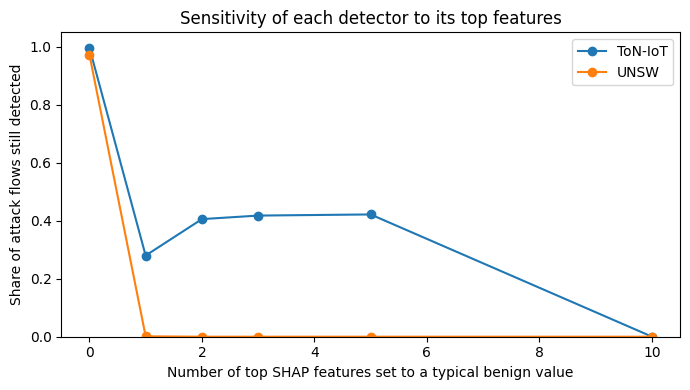

In [43]:
# Cell 25: Replace the top-k SHAP features of attack flows with benign values
rob_rows, ttl_rows = [], []
for name, (tr, te) in splits.items():
    ranked = imp[name].sort_values(ascending=False).index.tolist()
    ben_med = tr.loc[tr[TARGET] == 0, cols].median()
    att = te.loc[te[TARGET] == 1, cols].copy()

    for k in [0, 1, 2, 3, 5, 10]:
        mod = att.copy()
        for c in ranked[:k]:
            mod[c] = ben_med[c]
        rate = (models[name].predict_proba(mod)[:, 1] >= 0.5).mean()
        rob_rows.append({"network": name, "features_changed": k,
                         "attack_detection_rate": round(float(rate), 4),
                         "changed": ", ".join(ranked[:k])})

    mod = att.copy()
    for c in ["MIN_TTL", "MAX_TTL"]:
        mod[c] = ben_med[c]
    rate = (models[name].predict_proba(mod)[:, 1] >= 0.5).mean()
    ttl_rows.append({"network": name, "changed": "MIN_TTL + MAX_TTL only",
                     "attack_detection_rate": round(float(rate), 4)})

rob = pd.DataFrame(rob_rows)
rob.to_csv(f"{OUT_DIR}/results_robustness.csv", index=False)
display(rob)
display(pd.DataFrame(ttl_rows))

fig, ax = plt.subplots(figsize=(7, 4))
for name, g in rob.groupby("network"):
    ax.plot(g["features_changed"], g["attack_detection_rate"], marker="o", label=name)
ax.set_xlabel("Number of top SHAP features set to a typical benign value")
ax.set_ylabel("Share of attack flows still detected")
ax.set_ylim(0, 1.05)
ax.set_title("Sensitivity of each detector to its top features")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_robustness.png", dpi=200)
plt.show()

Package everything for the app and GitHub

In [42]:
# Cell 26: Save everything the Streamlit app and GitHub repo will need
import json, shutil

APP_DIR = "/content/app_assets"
for folder in ["models", "demo", "results"]:
    os.makedirs(f"{APP_DIR}/{folder}", exist_ok=True)

# 1) The two main models (no-ports features, same settings as the experiments)
models["UNSW"].save_model(f"{APP_DIR}/models/model_unsw.json")
models["ToN-IoT"].save_model(f"{APP_DIR}/models/model_toniot.json")

# 2) One "adapted" model: UNSW + 50 labeled attacks and 50 benign flows from ToN-IoT
src_tr = splits["UNSW"][0]
tgt_tr, tgt_te = splits["ToN-IoT"]
sub = pd.concat([tgt_tr[tgt_tr[TARGET] == 1].sample(50, random_state=1),
                 tgt_tr[tgt_tr[TARGET] == 0].sample(50, random_state=1)])
X = pd.concat([src_tr[cols], sub[cols]])
y = pd.concat([src_tr[TARGET], sub[TARGET]])
w = np.concatenate([np.ones(len(src_tr)), np.full(len(sub), 20)])
m_ad = XGBClassifier(n_estimators=150, max_depth=8, learning_rate=0.1,
                     tree_method="hist", n_jobs=-1,
                     eval_metric="logloss", random_state=42)
m_ad.fit(X, y, sample_weight=w)
m_ad.save_model(f"{APP_DIR}/models/model_unsw_adapted_toniot.json")
print("Adapted model F1 on ToN-IoT test:",
      round(evaluate(m_ad, tgt_te[cols], tgt_te[TARGET])["F1"], 4))

# 3) Feature list
json.dump(cols, open(f"{APP_DIR}/feature_list.json", "w"), indent=2)

# 4) Tiny demo files (500 flows per network; no IP addresses, no ports)
for name, fname in [("UNSW", "demo_unsw.csv"), ("ToN-IoT", "demo_toniot.csv")]:
    te = splits[name][1]
    te.sample(500, random_state=1)[cols + [TARGET]].to_csv(f"{APP_DIR}/demo/{fname}", index=False)

# 5) Binned feature distributions (counts only, no raw rows) for the shift explorer
pool = pd.concat([df_unsw[cols], df_ton[cols]])
hist = {}
for c in cols:
    allv = pool[c].astype("float64").dropna().values
    edges = np.unique(np.quantile(allv, np.linspace(0, 1, 21)))
    if len(edges) < 2:
        continue
    entry = {"edges": edges.tolist()}
    for name, df in [("UNSW", df_unsw), ("ToN-IoT", df_ton)]:
        v = df[c].astype("float64").dropna().values
        counts, _ = np.histogram(v, bins=edges)
        entry[name] = (counts / counts.sum()).tolist()
    hist[c] = entry
json.dump(hist, open(f"{APP_DIR}/feature_histograms.json", "w"))

# 6) Copy result tables and figures
for f in glob.glob(f"{OUT_DIR}/*.csv") + glob.glob(f"{OUT_DIR}/*.png"):
    shutil.copy(f, f"{APP_DIR}/results/")

# 7) Show what we have, then zip and download
for f in sorted(glob.glob(f"{APP_DIR}/**/*", recursive=True)):
    if os.path.isfile(f):
        print(f"{os.path.getsize(f)/1e3:8.0f} KB  {f.replace(APP_DIR + '/', '')}")

!cd /content && zip -qr app_assets.zip app_assets
from google.colab import files
files.download("/content/app_assets.zip")

Adapted model F1 on ToN-IoT test: 0.9402
      95 KB  demo/demo_toniot.csv
     107 KB  demo/demo_unsw.csv
      18 KB  feature_histograms.json
       1 KB  feature_list.json
    1768 KB  models/model_toniot.json
     935 KB  models/model_unsw.json
    1044 KB  models/model_unsw_adapted_toniot.json
       2 KB  results/feature_shift.csv
      82 KB  results/fig_f1_within_vs_cross.png
     124 KB  results/fig_feature_shift.png
      84 KB  results/fig_few_labels.png
      99 KB  results/fig_few_labels_seeds.png
     132 KB  results/fig_pruning.png
      89 KB  results/fig_robustness.png
     127 KB  results/fig_shap_top_features.png
       0 KB  results/results_few_labels.csv
       3 KB  results/results_few_labels_seeds_raw.csv
       0 KB  results/results_pruning.csv
       0 KB  results/results_quantile.csv
       1 KB  results/results_robustness.csv
       0 KB  results/results_shared_families.csv
       0 KB  results/results_ttl_ablation.csv
       1 KB  results/results_xgb.csv
   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>